In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


import warnings
warnings.filterwarnings('ignore')

In [3]:

df = pd.read_csv('./dataset/Electric_Vehicle_Population_Data.csv')


display(df.head())


df.info()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,KM8K33AGXL,King,Seattle,WA,98103.0,2020,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,258,0,43.0,249675142,POINT (-122.34301 47.659185),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10
1,1C4RJYB61N,King,Bothell,WA,98011.0,2022,JEEP,GRAND CHEROKEE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25,0,1.0,233928502,POINT (-122.20578 47.762405),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,1C4RJYD61P,Yakima,Yakima,WA,98908.0,2023,JEEP,GRAND CHEROKEE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25,0,14.0,229675939,POINT (-120.6027202 46.5965625),PACIFICORP,5.307700e+10
3,5YJ3E1EA7J,King,Kirkland,WA,98034.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215,0,45.0,104714466,POINT (-122.209285 47.71124),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
4,WBY7Z8C5XJ,Thurston,Olympia,WA,98501.0,2018,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,97,0,22.0,185498386,POINT (-122.89692 47.043535),PUGET SOUND ENERGY INC,5.306701e+10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150482 entries, 0 to 150481
Data columns (total 17 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         150482 non-null  object 
 1   County                                             150479 non-null  object 
 2   City                                               150479 non-null  object 
 3   State                                              150482 non-null  object 
 4   Postal Code                                        150479 non-null  float64
 5   Model Year                                         150482 non-null  int64  
 6   Make                                               150482 non-null  object 
 7   Model                                              150482 non-null  object 
 8   Electric Vehicle Type                              150482 non-null  object

In [4]:

selected_columns = ['Model Year', 'Make', 'Electric Range', 'Electric Vehicle Type']
df_clean = df[selected_columns].copy()


df_clean = df_clean.dropna()

print(f"Jumlah baris setelah dibersihkan: {df_clean.shape[0]}")


print(df_clean['Electric Vehicle Type'].value_counts())

Jumlah baris setelah dibersihkan: 150482
Electric Vehicle Type
Battery Electric Vehicle (BEV)            116807
Plug-in Hybrid Electric Vehicle (PHEV)     33675
Name: count, dtype: int64


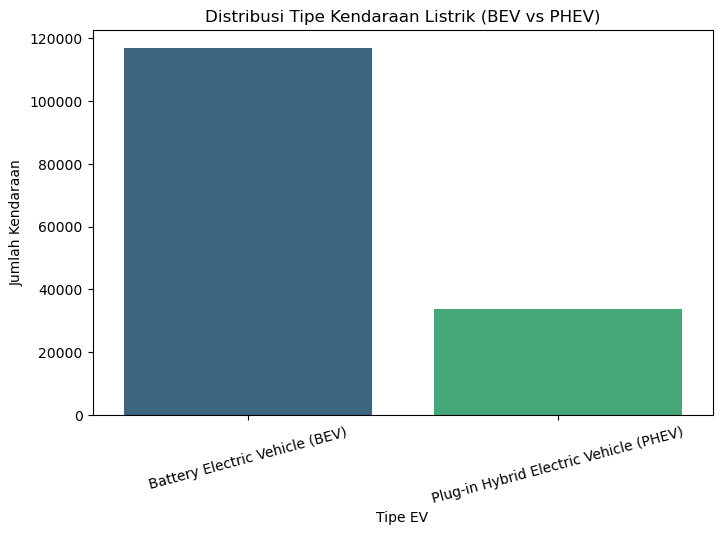

In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='Electric Vehicle Type', palette='viridis')
plt.title('Distribusi Tipe Kendaraan Listrik (BEV vs PHEV)')
plt.ylabel('Jumlah Kendaraan')
plt.xlabel('Tipe EV')
plt.xticks(rotation=15)
plt.show()

In [6]:

le_make = LabelEncoder()


df_clean['Make_Encoded'] = le_make.fit_transform(df_clean['Make'])


X = df_clean[['Model Year', 'Make_Encoded', 'Electric Range']]
y = df_clean['Electric Vehicle Type']

display(X.head())

,Model Year,Make_Encoded,Electric Range
0,2020,13,258
1,2022,15,25
2,2023,15,25
3,2018,31,215
4,2018,4,97


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data latih: {X_train.shape[0]}")
print(f"Jumlah data uji: {X_test.shape[0]}")

Jumlah data latih: 120385
Jumlah data uji: 30097


In [8]:

model = RandomForestClassifier(random_state=42, n_estimators=100)


model.fit(X_train, y_train)

print("Model selesai dilatih!")

Model selesai dilatih!


In [9]:

y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Model: {accuracy * 100:.2f}%\n")


print("Classification Report:")
print(classification_report(y_test, y_pred))

Akurasi Model: 100.00%

Classification Report:
                                        precision    recall  f1-score   support

        Battery Electric Vehicle (BEV)       1.00      1.00      1.00     23392
Plug-in Hybrid Electric Vehicle (PHEV)       1.00      1.00      1.00      6705

                              accuracy                           1.00     30097
                             macro avg       1.00      1.00      1.00     30097
                          weighted avg       1.00      1.00      1.00     30097

